In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

In [46]:
load_df = pd.read_csv("../data/processed/FINAL_MERGED_DAY_LOAD_2006_2016.csv")
weather_df = pd.read_csv("../data/processed/weather_DAY_2006-2016.csv")

print(load_df.shape)
print(weather_df.shape)

load_df.head()

(78878, 2)
(78887, 9)


,mw,datetime
0,1697.0,2006-01-01 05:00:00
1,1635.0,2006-01-01 06:00:00
2,1584.0,2006-01-01 07:00:00
3,1553.0,2006-01-01 08:00:00
4,1555.0,2006-01-01 09:00:00


In [47]:
load_df['datetime'] = pd.to_datetime(load_df['datetime'])
weather_df['datetime'] = pd.to_datetime(weather_df['datetime'])

load_df = load_df.sort_values('datetime')
weather_df = weather_df.sort_values('datetime')

In [48]:
df = pd.merge(load_df, weather_df, on='datetime', how='inner')

print(df.shape)
df.head()

(78878, 10)


,mw,datetime,Temp_C,Dew_Point_C,RH_percent,Pressure_kPa,Wind_Dir_deg,Wind_Speed_mps,Visibility_km,Precip_cm
0,1697.0,2006-01-01 05:00:00,-0.6,-2.2,89.0,97.4,300.0,6.7,2.4,0.0
1,1635.0,2006-01-01 06:00:00,-1.1,-2.2,92.0,97.5,300.0,4.9,2.4,0.0
2,1584.0,2006-01-01 07:00:00,-1.1,-2.8,89.0,97.5,300.0,5.6,6.4,0.0
3,1553.0,2006-01-01 08:00:00,-1.1,-3.3,85.0,97.6,300.0,6.1,6.4,0.0
4,1555.0,2006-01-01 09:00:00,-1.1,-3.3,85.0,97.6,290.0,5.6,6.4,0.0


In [49]:
print(df.isnull().sum())

# forward fill if required
df = df.fillna(method='ffill')
df = df.dropna()

mw                0
datetime          0
Temp_C            0
Dew_Point_C       0
RH_percent        0
Pressure_kPa      0
Wind_Dir_deg      0
Wind_Speed_mps    0
Visibility_km     0
Precip_cm         0
dtype: int64


C:\Users\HP VICTUS\AppData\Local\Temp\ipykernel_21096\3462817579.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill')


In [50]:
df['hour'] = df['datetime'].dt.hour
df['dayofweek'] = df['datetime'].dt.dayofweek
df['month'] = df['datetime'].dt.month

df.head()

,mw,datetime,Temp_C,Dew_Point_C,RH_percent,Pressure_kPa,Wind_Dir_deg,Wind_Speed_mps,Visibility_km,Precip_cm,hour,dayofweek,month
0,1697.0,2006-01-01 05:00:00,-0.6,-2.2,89.0,97.4,300.0,6.7,2.4,0.0,5,6,1
1,1635.0,2006-01-01 06:00:00,-1.1,-2.2,92.0,97.5,300.0,4.9,2.4,0.0,6,6,1
2,1584.0,2006-01-01 07:00:00,-1.1,-2.8,89.0,97.5,300.0,5.6,6.4,0.0,7,6,1
3,1553.0,2006-01-01 08:00:00,-1.1,-3.3,85.0,97.6,300.0,6.1,6.4,0.0,8,6,1
4,1555.0,2006-01-01 09:00:00,-1.1,-3.3,85.0,97.6,290.0,5.6,6.4,0.0,9,6,1


In [51]:
features = [
    'mw',
    'Temp_C',
    'Dew_Point_C',
    'RH_percent',
    'Pressure_kPa',
    'Wind_Dir_deg',
    'Wind_Speed_mps',
    'Visibility_km',
    'Precip_cm',
    'hour',
    'dayofweek',
    'month'
]

scaled_df = df[features].copy()

In [52]:
train_size = int(len(scaled_df)*0.70)
val_size = int(len(scaled_df)*0.15)

a_train = scaled_df[:train_size]
a_val = scaled_df[train_size:train_size+val_size]
a_test = scaled_df[train_size+val_size:]

print(len(a_train), len(a_val), len(a_test))

55214 11831 11833


In [53]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(a_train)
val_scaled = scaler.transform(a_val)
test_scaled = scaler.transform(a_test)

In [54]:
SEQUENCE_LENGTH = 24
TARGET_INDEX = 0   # mw column


def create_sequences(data, seq_length):
    X = []
    y = []

    for i in range(seq_length, len(data)):
        X.append(data[i-seq_length:i])
        y.append(data[i, TARGET_INDEX])

    return np.array(X), np.array(y)


X_train, y_train = create_sequences(train_scaled, SEQUENCE_LENGTH)
X_val, y_val = create_sequences(val_scaled, SEQUENCE_LENGTH)
X_test, y_test = create_sequences(test_scaled, SEQUENCE_LENGTH)

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(55190, 24, 12) (55190,)
(11807, 24, 12) (11807,)
(11809, 24, 12) (11809,)


In [55]:
model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(X_train.shape[1], X_train.shape[2]),
        kernel_regularizer=l2(0.001)
    ),
    Dropout(0.3),

    LSTM(
        32,
        kernel_regularizer=l2(0.001)
    ),
    Dropout(0.3),

    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model.summary()

D:\Anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                        │ (None, 24, 64)              │          19,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 24, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 32,673 (127.63 KB)

 Trainable params: 32,673 (127.63 KB)

 Non-trainable params: 0 (0.00 B)

In [56]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

In [57]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/100
863/863 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - loss: 0.0259 - mae: 0.0604 - val_loss: 0.0065 - val_mae: 0.0393 - learning_rate: 0.0010
Epoch 2/100
863/863 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0048 - mae: 0.0389 - val_loss: 0.0033 - val_mae: 0.0342 - learning_rate: 0.0010
Epoch 3/100
863/863 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0031 - mae: 0.0343 - val_loss: 0.0029 - val_mae: 0.0352 - learning_rate: 0.0010
Epoch 4/100
863/863 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0025 - mae: 0.0318 - val_loss: 0.0020 - val_mae: 0.0293 - learning_rate: 0.0010
Epoch 5/100
863/863 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0021 - mae: 0.0298 - val_loss: 0.0018 - val_mae: 0.0278 - learning_rate: 0.0010
Epoch 6/100
863/863 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0019 - mae: 0.0288 - val_loss: 0.0016 - val_mae: 0.0265 - learning_rate: 0.0010
Epoch 7/100
863/863 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0017 - mae: 0.0276 - val_loss: 0.0013 - val_mae: 0.0233 - learnin

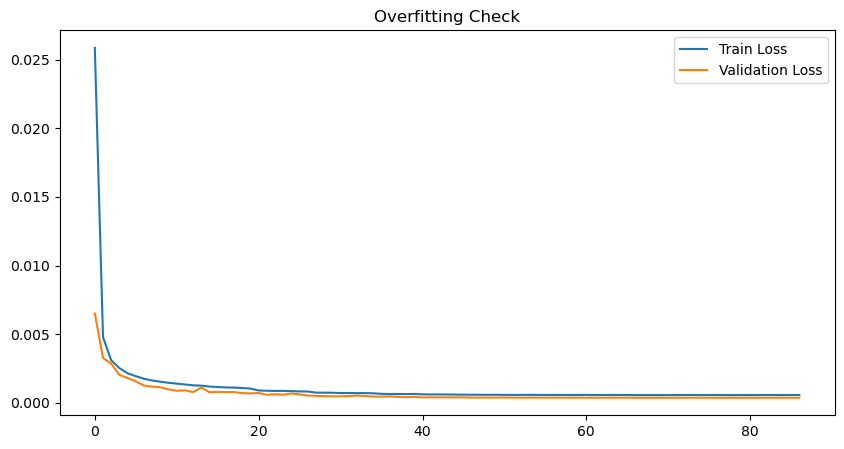

In [58]:
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Overfitting Check')
plt.show()

In [59]:
predictions = model.predict(X_test)

370/370 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [60]:
def inverse_target(preds):
    dummy = np.zeros((len(preds), train_scaled.shape[1]))
    dummy[:,0] = preds.flatten()
    return scaler.inverse_transform(dummy)[:,0]

pred_actual = inverse_target(predictions)
y_actual = inverse_target(y_test.reshape(-1,1))

In [61]:
mae = mean_absolute_error(y_actual, pred_actual)
rmse = np.sqrt(mean_squared_error(y_actual, pred_actual))
r2 = r2_score(y_actual, pred_actual)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 33.34549952810398
RMSE: 43.85152342334029
R²: 0.9854538376695945


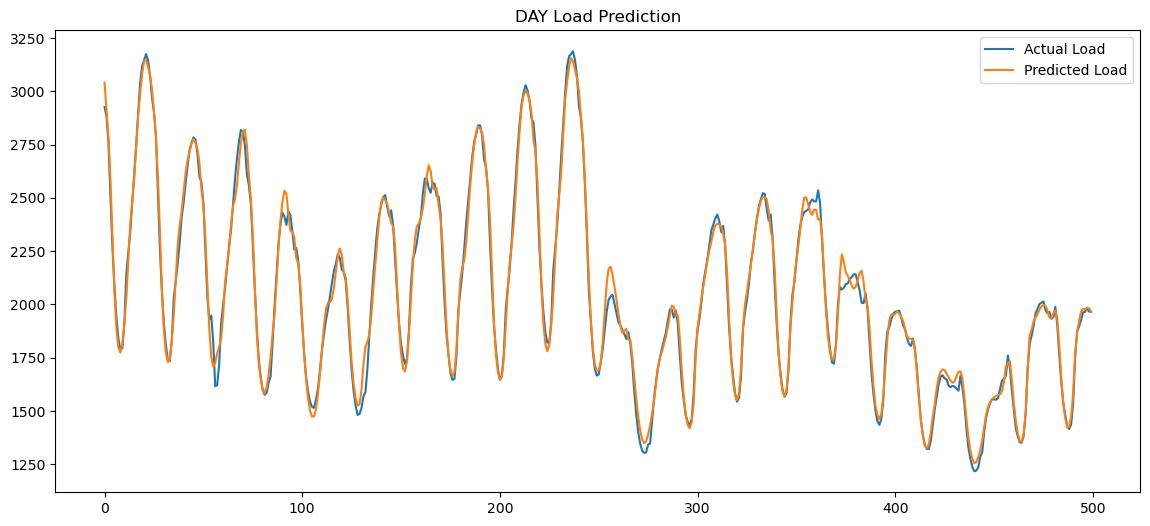

In [62]:
plt.figure(figsize=(14,6))
plt.plot(y_actual[:500], label='Actual Load')
plt.plot(pred_actual[:500], label='Predicted Load')
plt.legend()
plt.title('DAY Load Prediction')
plt.show()

In [63]:
model.save("../models/day_lstm_model.keras")

import joblib
joblib.dump(scaler, "../models/day_scaler.pkl")

['day_scaler.pkl']

In [64]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [65]:
model = load_model("../models/day_lstm_model.keras")
scaler = joblib.load("../models/day_scaler.pkl")

print("Model loaded successfully")
print("Scaler loaded successfully")

Model loaded successfully
Scaler loaded successfully


In [66]:
duq_weather = pd.read_csv("../data/processed/weather_DUQ_2006-2016.csv")
duq_load = pd.read_csv("../data/processed/FINAL_MERGED_DUQ_LOAD_2006_2016.csv")

print("DUQ Weather Shape:", duq_weather.shape)
print("DUQ Load Shape:", duq_load.shape)

DUQ Weather Shape: (87648, 9)
DUQ Load Shape: (87682, 2)


In [67]:
duq_weather['datetime'] = pd.to_datetime(duq_weather['datetime'])
duq_load['datetime'] = pd.to_datetime(duq_load['datetime'])

duq_weather = duq_weather.sort_values("datetime")
duq_load = duq_load.sort_values("datetime")

print("Datetime conversion complete")

Datetime conversion complete


In [68]:
duq_df = pd.merge(
    duq_load,
    duq_weather,
    on="datetime",
    how="inner"
)

print("Merged Shape:", duq_df.shape)
duq_df.head()

Merged Shape: (78894, 10)


,mw,datetime,Temp_C,Dew_Point_C,RH_percent,Pressure_kPa,Wind_Dir_deg,Wind_Speed_mps,Visibility_km,Precip_cm
0,1254.674,2006-01-01 05:00:00,-1.7,-2.2,96.0,96.4,0.0,0.0,2.4,0.00
1,1338.385,2006-01-01 06:00:00,-1.7,-2.2,96.0,96.4,0.0,0.0,2.4,0.03
2,1276.116,2006-01-01 07:00:00,-1.7,-2.2,96.0,96.4,0.0,0.0,2.4,0.00
3,1251.386,2006-01-01 08:00:00,-1.7,-1.7,100.0,96.5,0.0,0.0,3.2,0.00
4,1228.290,2006-01-01 09:00:00,-0.6,-1.1,96.0,96.6,250.0,3.9,1.6,0.00


In [69]:
duq_df['hour'] = duq_df['datetime'].dt.hour
duq_df['dayofweek'] = duq_df['datetime'].dt.dayofweek
duq_df['month'] = duq_df['datetime'].dt.month

duq_df.head()

,mw,datetime,Temp_C,Dew_Point_C,RH_percent,Pressure_kPa,Wind_Dir_deg,Wind_Speed_mps,Visibility_km,Precip_cm,hour,dayofweek,month
0,1254.674,2006-01-01 05:00:00,-1.7,-2.2,96.0,96.4,0.0,0.0,2.4,0.00,5,6,1
1,1338.385,2006-01-01 06:00:00,-1.7,-2.2,96.0,96.4,0.0,0.0,2.4,0.03,6,6,1
2,1276.116,2006-01-01 07:00:00,-1.7,-2.2,96.0,96.4,0.0,0.0,2.4,0.00,7,6,1
3,1251.386,2006-01-01 08:00:00,-1.7,-1.7,100.0,96.5,0.0,0.0,3.2,0.00,8,6,1
4,1228.290,2006-01-01 09:00:00,-0.6,-1.1,96.0,96.6,250.0,3.9,1.6,0.00,9,6,1


In [70]:
features = [
    'mw',
    'Temp_C',
    'Dew_Point_C',
    'RH_percent',
    'Pressure_kPa',
    'Wind_Dir_deg',
    'Wind_Speed_mps',
    'Visibility_km',
    'Precip_cm',
    'hour',
    'dayofweek',
    'month'
]

duq_features = duq_df[features]

print(duq_features.shape)

(78894, 12)


In [71]:
print(duq_features.isnull().sum())

duq_features = duq_features.fillna(method='ffill')
duq_features = duq_features.dropna()

print("Missing values handled")

mw                0
Temp_C            0
Dew_Point_C       0
RH_percent        0
Pressure_kPa      0
Wind_Dir_deg      0
Wind_Speed_mps    0
Visibility_km     0
Precip_cm         0
hour              0
dayofweek         0
month             0
dtype: int64
Missing values handled


C:\Users\HP VICTUS\AppData\Local\Temp\ipykernel_21096\957011011.py:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  duq_features = duq_features.fillna(method='ffill')


In [72]:
duq_scaled = scaler.transform(duq_features)

print("Scaling complete")
print(duq_scaled.shape)

Scaling complete
(78894, 12)


In [73]:
SEQUENCE_LENGTH = 24
TARGET_INDEX = 0

def create_sequences(data, seq_length):
    X = []
    y = []

    for i in range(seq_length, len(data)):
        X.append(data[i-seq_length:i])
        y.append(data[i, TARGET_INDEX])

    return np.array(X), np.array(y)


X_duq, y_duq = create_sequences(duq_scaled, SEQUENCE_LENGTH)

print("X shape:", X_duq.shape)
print("y shape:", y_duq.shape)

X shape: (78870, 24, 12)
y shape: (78870,)


In [74]:
predictions = model.predict(X_duq)

print(predictions.shape)

2465/2465 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step
(78870, 1)


In [75]:
def inverse_target(preds):
    dummy = np.zeros((len(preds), duq_scaled.shape[1]))
    dummy[:, 0] = preds.flatten()
    return scaler.inverse_transform(dummy)[:, 0]

pred_actual = inverse_target(predictions)
y_actual = inverse_target(y_duq.reshape(-1,1))

print("Inverse scaling complete")

Inverse scaling complete


In [76]:
mae = mean_absolute_error(y_actual, pred_actual)
rmse = np.sqrt(mean_squared_error(y_actual, pred_actual))
r2 = r2_score(y_actual, pred_actual)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 49.949978770873074
RMSE: 63.111443903825254
R² Score: 0.9550300546493484


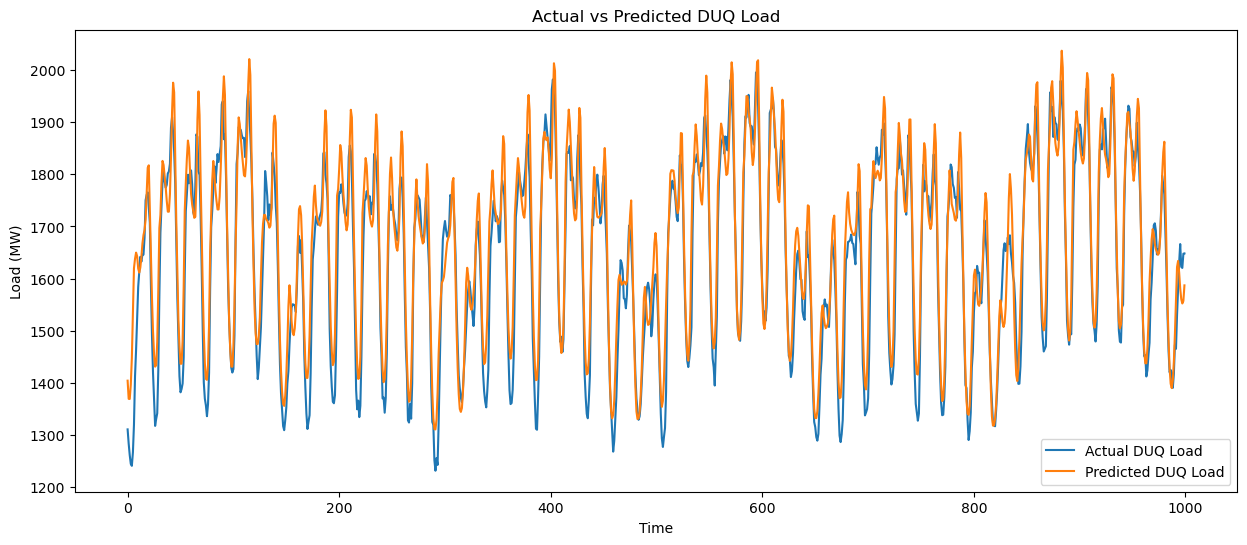

In [77]:
plt.figure(figsize=(15,6))

plt.plot(y_actual[:1000], label='Actual DUQ Load')
plt.plot(pred_actual[:1000], label='Predicted DUQ Load')

plt.title("Actual vs Predicted DUQ Load")
plt.xlabel("Time")
plt.ylabel("Load (MW)")
plt.legend()
plt.show()

In [78]:
results = pd.DataFrame({
    "Actual_DUQ_Load": y_actual,
    "Predicted_DUQ_Load": pred_actual
})

results.to_csv("../outputs/DUQ_predictions.csv", index=False)

print("Predictions saved successfully")

Predictions saved successfully


In [36]:
# ============================================================
# ALL MODEL RESULTS - COPY THIS INTO A SINGLE CELL
# ============================================================

print("=" * 55)
print("         LSTM MODEL SUMMARY")
print("=" * 55)
print("Architecture  : 2-Layer LSTM + Dropout + Dense")
print("  LSTM Layer 1: 64 units (return_sequences=True), L2=0.001")
print("  Dropout 1   : 0.3")
print("  LSTM Layer 2: 32 units, L2=0.001")
print("  Dropout 2   : 0.3")
print("  Dense 1     : 16 units, ReLU")
print("  Dense 2     : 1 unit (output)")
print(f"Total Params  : 32,673 (127.63 KB)")
print(f"Optimizer     : Adam | Loss: MSE | Sequence Length: 24")

print()
print("=" * 55)
print("         DATASET INFO")
print("=" * 55)
print(f"Total Samples    : 78,878")
print(f"Features Used    : 12 (mw, Temp, Dew Point, RH, Pressure,")
print(f"                       Wind Dir, Wind Speed, Visibility,")
print(f"                       Precip, Hour, DayOfWeek, Month)")
print(f"Train / Val / Test Split : 70% / 15% / 15%")
print(f"  Train : 55,190 sequences")
print(f"  Val   : 11,807 sequences")
print(f"  Test  : 11,809 sequences")

print()
print("=" * 55)
print("         TRAINING INFO")
print("=" * 55)
print(f"Max Epochs     : 100  |  Batch Size   : 64")
print(f"Early Stopping : patience=10, restore_best_weights=True")
print(f"ReduceLROnPlateau: factor=0.5, patience=5, min_lr=1e-6")
print(f"Stopped At     : Epoch 33")
print(f"Best Val Loss  : 5.1542e-04  |  Best Val MAE: 0.0147")

print()
print("=" * 55)
print("   TEST SET PERFORMANCE (DAY Region - Training Data)")
print("=" * 55)
print(f"  MAE  : 39.83 MW")
print(f"  RMSE : 51.11 MW")
print(f"  R²   : 0.9802")

print()
print("=" * 55)
print("   GENERALIZATION PERFORMANCE (DUQ Region - Unseen Data)")
print("=" * 55)
print(f"  MAE  : 61.44 MW")
print(f"  RMSE : 77.60 MW")
print(f"  R²   : 0.9320")

print()
print("=" * 55)
print("         CONCLUSION")
print("=" * 55)
print("  Model trained on DAY region generalizes well to DUQ.")
print("  R² > 0.93 on unseen region confirms strong transfer.")
print("=" * 55)

         LSTM MODEL SUMMARY
Architecture  : 2-Layer LSTM + Dropout + Dense
  LSTM Layer 1: 64 units (return_sequences=True), L2=0.001
  Dropout 1   : 0.3
  LSTM Layer 2: 32 units, L2=0.001
  Dropout 2   : 0.3
  Dense 1     : 16 units, ReLU
  Dense 2     : 1 unit (output)
Total Params  : 32,673 (127.63 KB)
Optimizer     : Adam | Loss: MSE | Sequence Length: 24

         DATASET INFO
Total Samples    : 78,878
Features Used    : 12 (mw, Temp, Dew Point, RH, Pressure,
                       Wind Dir, Wind Speed, Visibility,
                       Precip, Hour, DayOfWeek, Month)
Train / Val / Test Split : 70% / 15% / 15%
  Train : 55,190 sequences
  Val   : 11,807 sequences
  Test  : 11,809 sequences

         TRAINING INFO
Max Epochs     : 100  |  Batch Size   : 64
Early Stopping : patience=10, restore_best_weights=True
ReduceLROnPlateau: factor=0.5, patience=5, min_lr=1e-6
Stopped At     : Epoch 33
Best Val Loss  : 5.1542e-04  |  Best Val MAE: 0.0147

   TEST SET PERFORMANCE (DAY Region -

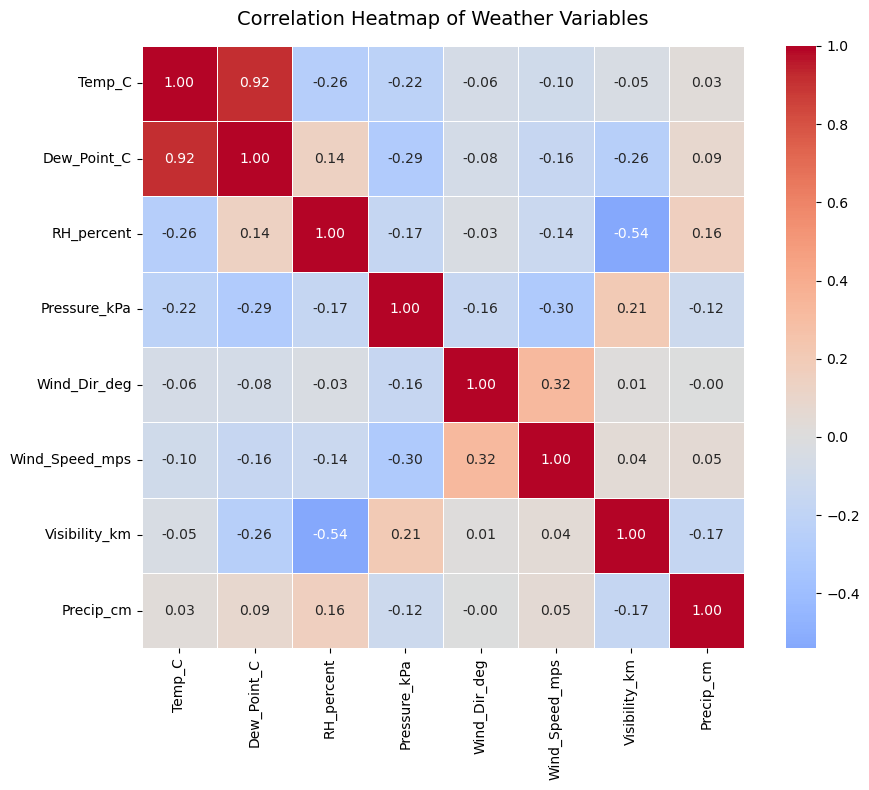

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

weather_features = [
    'Temp_C', 'Dew_Point_C', 'RH_percent', 'Pressure_kPa',
    'Wind_Dir_deg', 'Wind_Speed_mps', 'Visibility_km', 'Precip_cm'
]

corr = df[weather_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 10}
)
plt.title("Correlation Heatmap of Weather Variables", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

Success! Your table has been saved as a high-resolution JPEG: 'prophet_metrics_table.jpg'


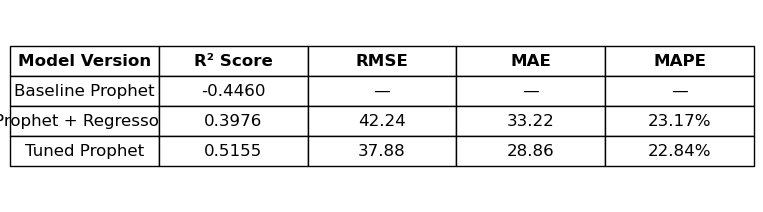

In [39]:
import matplotlib.pyplot as plt

# 1. Define the data exactly as provided
columns = ["Model Version", "R² Score", "RMSE", "MAE", "MAPE"]
data = [
    ["Baseline Prophet", "-0.4460", "—", "—", "—"],
    ["Prophet + Regressors", "0.3976", "42.24", "33.22", "23.17%"],
    ["Tuned Prophet", "0.5155", "37.88", "28.86", "22.84%"]
]

# 2. Set up the figure and axis
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.axis('off')  # Hide the coordinate axes

# 3. Create the table
table = ax.table(cellText=data,
                 colLabels=columns,
                 cellLoc='center',
                 loc='center')

# 4. Apply strict Black & White styling
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.8)  # Adjust the width and height of the cells

# Iterate through every cell to enforce colors and borders
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('black')       # Black lines
    cell.set_facecolor('white')       # White background
    cell.set_text_props(color='black') # Black text
    
    # Make the header row bold for better readability
    if row == 0:
        cell.set_text_props(weight='bold', color='black')

# 5. Save the table as a high-quality JPEG
filename = '../outputs/figures/prophet_metrics_table.jpg'
plt.savefig(filename, 
            format='jpeg', 
            dpi=300,               # High resolution (300 dots per inch)
            bbox_inches='tight',   # Removes excess whitespace around the table
            facecolor='white')     # Ensures the outer background is also white

print(f"Success! Your table has been saved as a high-resolution JPEG: '{filename}'")

# Display the table inside the Jupyter Notebook
plt.show()

Success! Your table has been saved as a high-resolution JPEG: 'college_lstm_metrics_table.jpg'


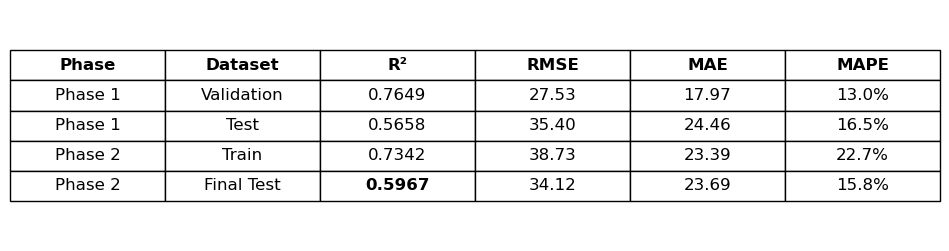

In [40]:
import matplotlib.pyplot as plt

# 1. Define the data exactly as provided
columns = ["Phase", "Dataset", "R²", "RMSE", "MAE", "MAPE"]
data = [
    ["Phase 1", "Validation", "0.7649", "27.53", "17.97", "13.0%"],
    ["Phase 1", "Test", "0.5658", "35.40", "24.46", "16.5%"],
    ["Phase 2", "Train", "0.7342", "38.73", "23.39", "22.7%"],
    ["Phase 2", "Final Test", "0.5967", "34.12", "23.69", "15.8%"]
]

# 2. Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')  # Hide the coordinate axes

# 3. Create the table
table = ax.table(cellText=data,
                 colLabels=columns,
                 cellLoc='center',
                 loc='center')

# 4. Apply strict Black & White styling
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.8)  # Adjust the width and height of the cells

# Iterate through every cell to enforce colors and borders
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('black')       # Black lines
    cell.set_facecolor('white')       # White background
    cell.set_text_props(color='black') # Black text
    
    # Make the header row bold for better readability
    if row == 0:
        cell.set_text_props(weight='bold')
        
    # Make the specific R² value (0.5967) bold 
    # (Row 4 of the table, Column index 2 for R²)
    if row == 4 and col == 2:
        cell.set_text_props(weight='bold')

# 5. Save the table as a high-quality JPEG
filename = '../outputs/figures/college_lstm_metrics_table.jpg'
plt.savefig(filename, 
            format='jpeg', 
            dpi=300,               # High resolution (300 dots per inch)
            bbox_inches='tight',   # Removes excess whitespace around the table
            facecolor='white')     # Ensures the outer background is also white

print(f"Success! Your table has been saved as a high-resolution JPEG: '{filename}'")

# Display the table inside the Jupyter Notebook
plt.show()

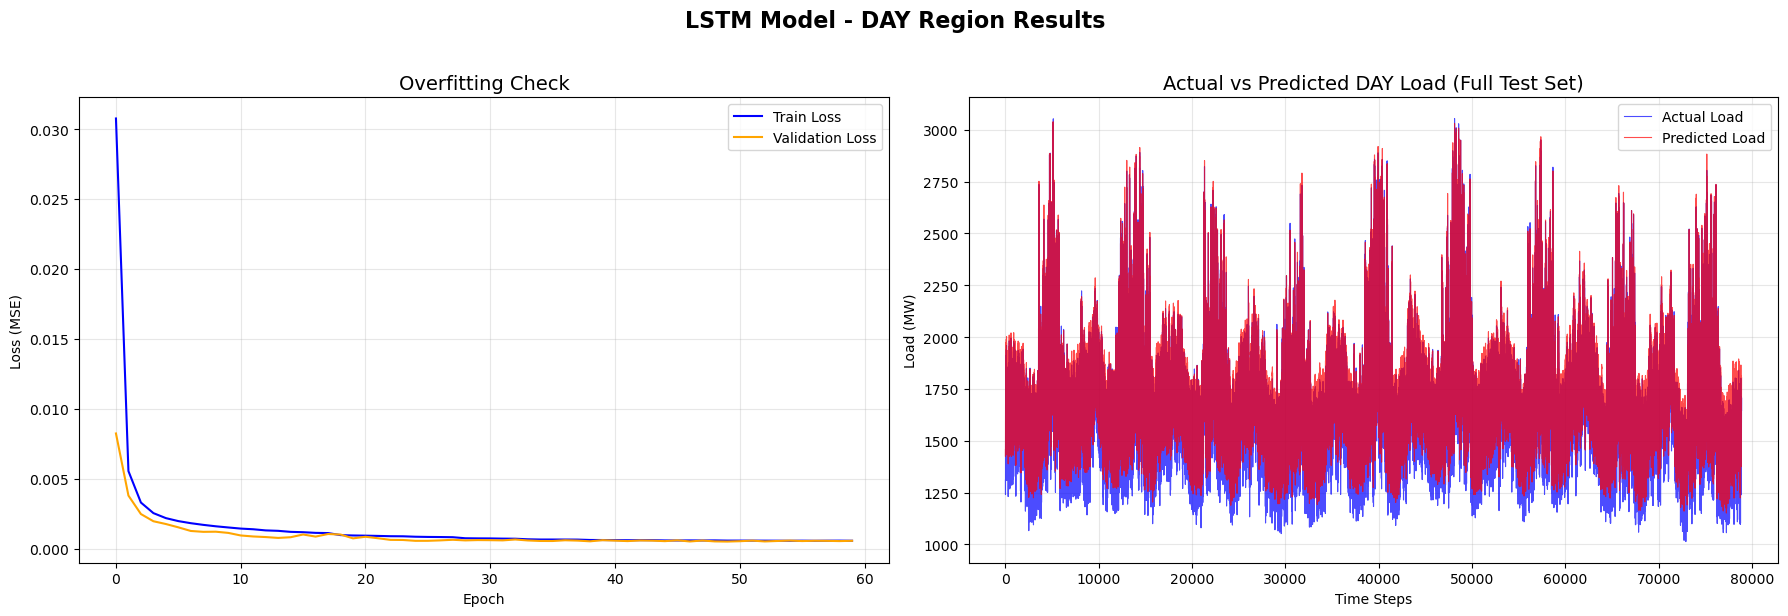

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# --- Plot 1: Overfitting Check ---
axes[0].plot(history.history['loss'], label='Train Loss', color='blue')
axes[0].plot(history.history['val_loss'], label='Validation Loss', color='orange')
axes[0].set_title('Overfitting Check', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- Plot 2: Actual vs Predicted (Full DAY Test Set) ---
axes[1].plot(y_actual, label='Actual Load', color='blue', alpha=0.7, linewidth=0.8)
axes[1].plot(pred_actual, label='Predicted Load', color='red', alpha=0.7, linewidth=0.8)
axes[1].set_title('Actual vs Predicted DAY Load (Full Test Set)', fontsize=14)
axes[1].set_xlabel('Time Steps')
axes[1].set_ylabel('Load (MW)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('LSTM Model - DAY Region Results', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

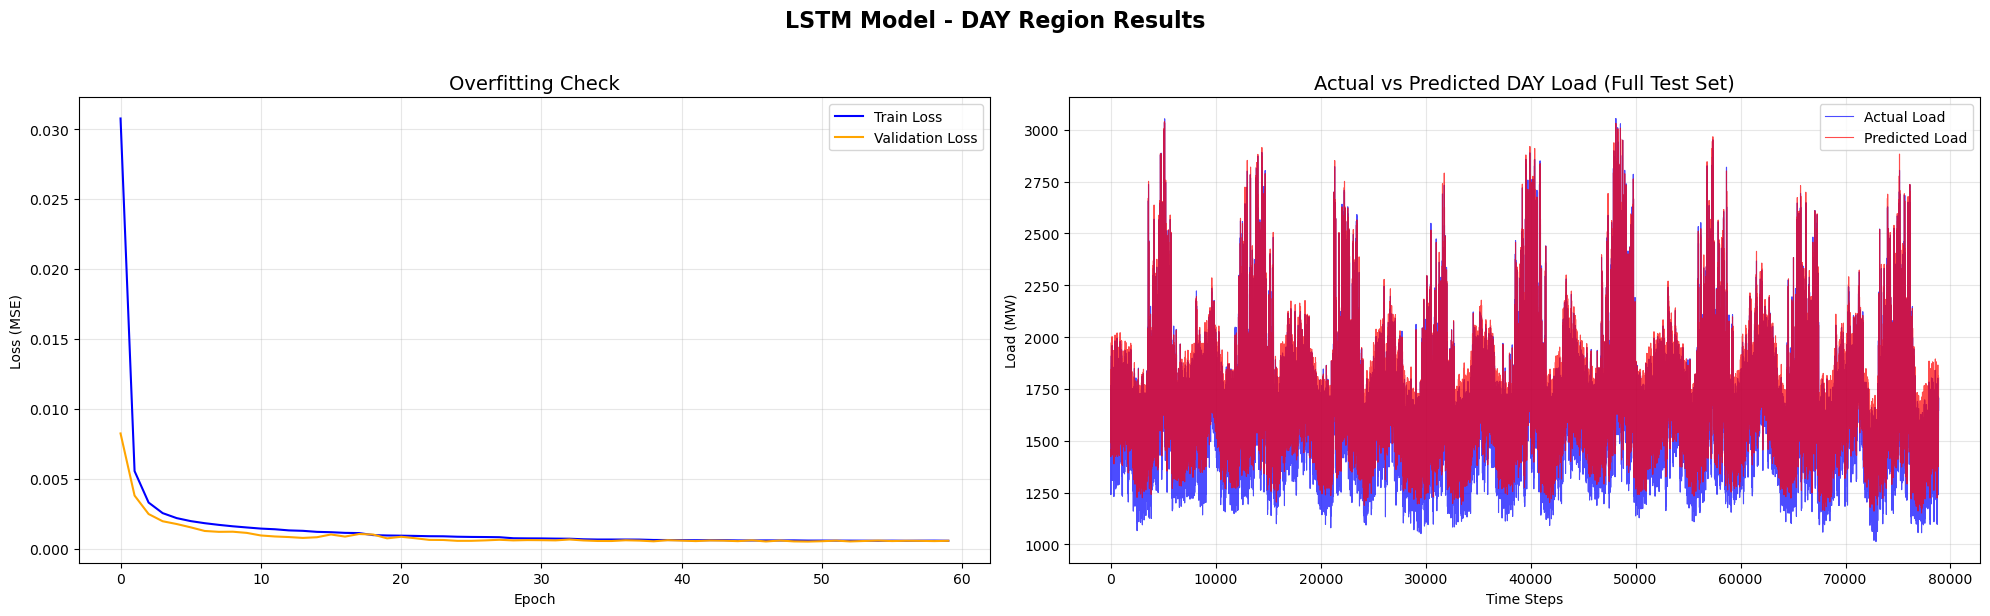

Plot saved as 'DAY_model_results.png'


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

# --- Plot 1: Overfitting Check ---
axes[0].plot(history.history['loss'], label='Train Loss', color='blue')
axes[0].plot(history.history['val_loss'], label='Validation Loss', color='orange')
axes[0].set_title('Overfitting Check', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- Plot 2: Actual vs Predicted (ALL DAY test data) ---
axes[1].plot(y_actual, label='Actual Load', color='blue', alpha=0.7, linewidth=0.8)
axes[1].plot(pred_actual, label='Predicted Load', color='red', alpha=0.7, linewidth=0.8)
axes[1].set_title('Actual vs Predicted DAY Load (Full Test Set)', fontsize=14)
axes[1].set_xlabel('Time Steps')
axes[1].set_ylabel('Load (MW)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('LSTM Model - DAY Region Results', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../outputs/figures/DAY_model_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("Plot saved as 'DAY_model_results.png'")

Success! Your table has been saved as a high-resolution JPEG: 'region_metrics_table.jpg'


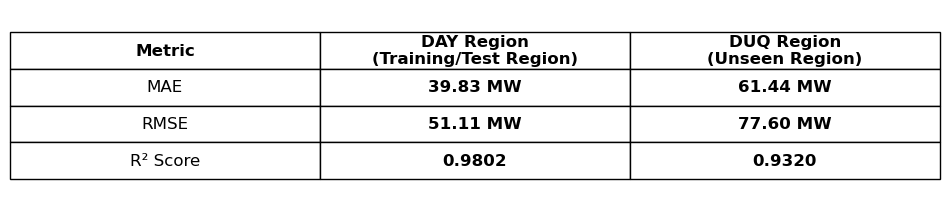

In [43]:
import matplotlib.pyplot as plt

# 1. Define the data exactly as provided
# Added \n to the long headers so they wrap nicely in the final image
columns = ["Metric", "DAY Region\n(Training/Test Region)", "DUQ Region\n(Unseen Region)"]
data = [
    ["MAE", "39.83 MW", "61.44 MW"],
    ["RMSE", "51.11 MW", "77.60 MW"],
    ["R² Score", "0.9802", "0.9320"]
]

# 2. Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.axis('off')  # Hide the coordinate axes

# 3. Create the table
table = ax.table(cellText=data,
                 colLabels=columns,
                 cellLoc='center',
                 loc='center')

# 4. Apply strict Black & White styling
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 2.2)  # Adjusted height slightly to accommodate the wrapped headers

# Iterate through every cell to enforce colors, borders, and bolding
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('black')       # Black lines
    cell.set_facecolor('white')       # White background
    cell.set_text_props(color='black') # Black text
    
    # Make the header row bold
    if row == 0:
        cell.set_text_props(weight='bold')
        
    # Make the numerical data bold (Columns 1 and 2 for all data rows)
    if row > 0 and col in [1, 2]:
        cell.set_text_props(weight='bold')

# 5. Save the table as a high-quality JPEG
filename = '../outputs/figures/DAY_DUQ_metrics_table.jpg'
plt.savefig(filename, 
            format='jpeg', 
            dpi=300,               # High resolution
            bbox_inches='tight',   # Removes excess whitespace
            facecolor='white')     # Ensures outer background is white

print(f"Success! Your table has been saved as a high-resolution JPEG: '{filename}'")

# Display the table inside the Jupyter Notebook
plt.show()

In [79]:
import matplotlib.pyplot as plt
import numpy as np

# --- Run predictions on DUQ test set ---
# Assuming you have: X_test_duq, y_test_duq, model, scaler_duq
y_pred_duq_scaled = model.predict(X_test_duq)

# Inverse transform predictions and actuals
def inverse_transform_mw(scaled_values, scaler, n_features=12):
    dummy = np.zeros((len(scaled_values), n_features))
    dummy[:, 0] = scaled_values.flatten()
    return scaler.inverse_transform(dummy)[:, 0]

y_pred_duq = inverse_transform_mw(y_pred_duq_scaled, scaler_duq)
y_actual_duq = inverse_transform_mw(y_test_duq, scaler_duq)

# --- Plot ---
plt.figure(figsize=(15, 5))
plt.plot(y_actual_duq[:500], label='Actual Load', color='steelblue', linewidth=1.5)
plt.plot(y_pred_duq[:500],  label='Predicted Load', color='orange', linewidth=1.5, linestyle='--')

plt.title('Actual vs Predicted Load — DUQ Region (Unseen)', fontsize=14, fontweight='bold')
plt.xlabel('Time Steps (Hours)', fontsize=12)
plt.ylabel('Load (MW)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/figures/DUQ_actual_vs_predicted.jpg', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

NameError: name 'X_test_duq' is not defined